# Customer Churn Prediction — Machine Learning

**Author:** Prathamesh Tirshu  
**Tools:** Python (Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Joblib)  
**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns) — a public sample dataset published by IBM.

## Business problem
A telecom company loses customers every month ("churn"). Winning a new customer costs much more than keeping an existing one.

**Goal:** predict which customers are likely to leave **before** they leave, so the retention team can target them with offers — and explain *why* they are at risk.

## Approach
1. Data cleaning and quality checks  
2. Exploratory data analysis (EDA)  
3. Pre-processing pipeline (one-hot encoding + scaling)  
4. Train and compare 3 models: **Logistic Regression, Random Forest, Gradient Boosting**  
5. Evaluate with cross-validation, ROC-AUC, precision / recall, confusion matrix  
6. Tune the decision threshold for the business goal  
7. Explain the model (feature importance) and measure business value (lift)  
8. Save the trained pipeline for reuse (`models/churn_model.joblib`)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
CHARTS = 'outputs/charts/'
RANDOM_STATE = 42

## 1. Load and clean the data

In [2]:
df = pd.read_csv('data/telco_customer_churn.csv')
print('Shape:', df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` is stored as **text**, not a number. Converting it shows a few blank values.

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
blank = df[df['TotalCharges'].isna()]
print('Blank TotalCharges:', len(blank))
blank[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


All blank rows have **tenure = 0** — they are brand-new customers who have not been billed yet. So the correct value is **0**, not the mean. (Filling with the mean would be wrong here — understanding *why* data is missing matters more than the fill method.)

In [5]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['Churn'] = (df['Churn'] == 'Yes').astype(int)
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df = df.drop(columns='customerID')   # an ID has no predictive meaning

print('Duplicates:', df.duplicated().sum(), '| Missing values:', df.isna().sum().sum())
print('Churn rate: {:.1%}'.format(df['Churn'].mean()))

Duplicates: 22 | Missing values: 0
Churn rate: 26.5%


The churn rate is about **26.5%**, so the classes are **imbalanced** (roughly 1 churner for every 3 who stay). Accuracy alone would be misleading — a model that predicts "no churn" for everyone would already be ~73% accurate. We will focus on **ROC-AUC, recall and precision**.

## 2. Exploratory data analysis

In [6]:
def churn_by(col):
    return df.groupby(col)['Churn'].agg(customers='count', churn_rate='mean').sort_values('churn_rate', ascending=False)

for col in ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']:
    print(churn_by(col).round(3), '\n')

                customers  churn_rate
Contract                             
Month-to-month       3875       0.427
One year             1473       0.113
Two year             1695       0.028 

                 customers  churn_rate
InternetService                       
Fiber optic           3096       0.419
DSL                   2421       0.190
No                    1526       0.074 

                           customers  churn_rate
PaymentMethod                                   
Electronic check                2365       0.453
Mailed check                    1612       0.191
Bank transfer (automatic)       1544       0.167
Credit card (automatic)         1522       0.152 

                     customers  churn_rate
TechSupport                               
No                        3473       0.416
Yes                       2044       0.152
No internet service       1526       0.074 



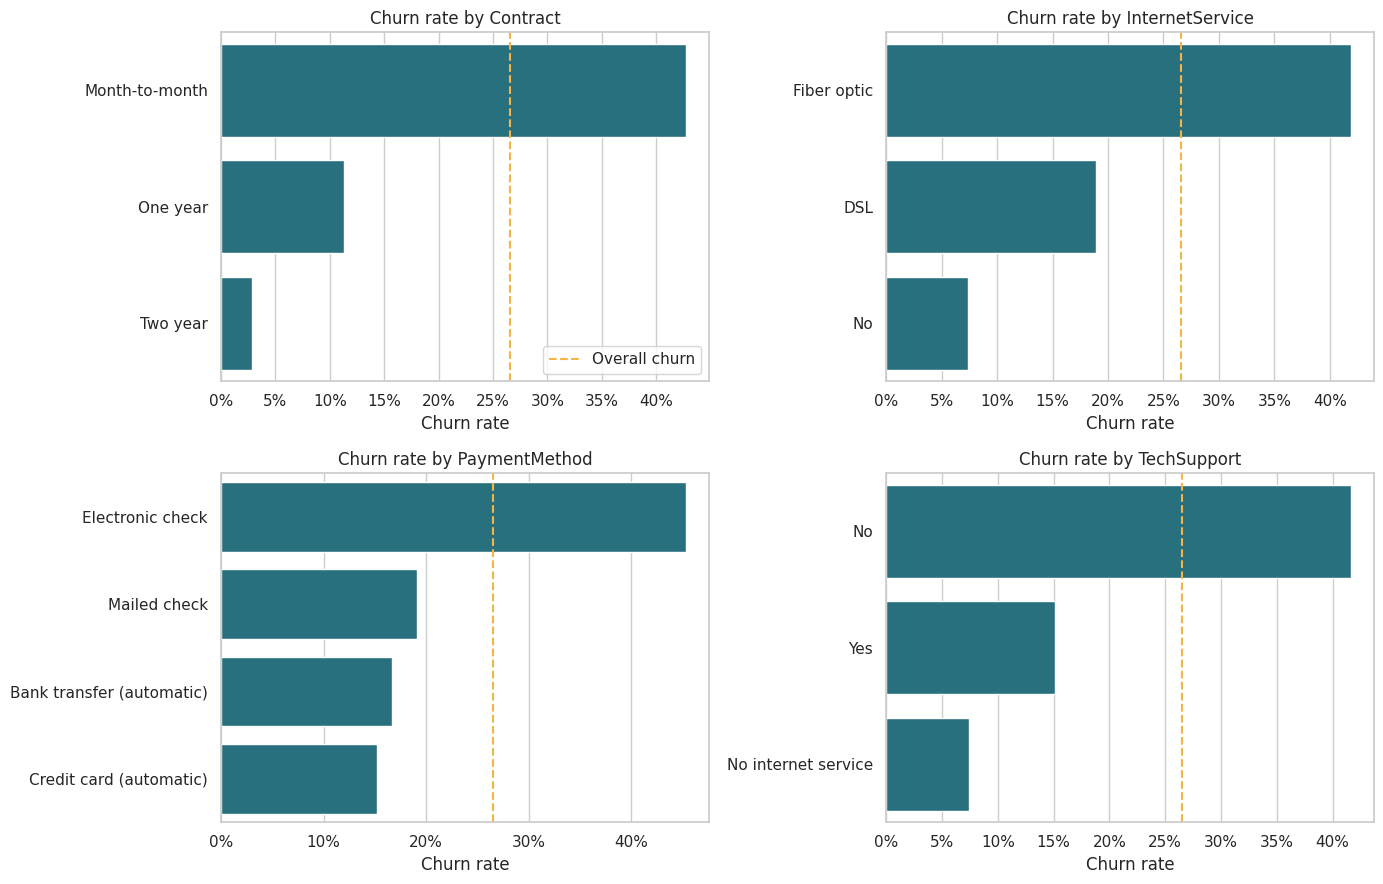

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']):
    t = churn_by(col).reset_index()
    sns.barplot(data=t, x='churn_rate', y=col, ax=ax, color='#1B7A8C')
    ax.axvline(df['Churn'].mean(), ls='--', color='#F5B446', label='Overall churn')
    ax.set_title(f'Churn rate by {col}'); ax.set_xlabel('Churn rate'); ax.set_ylabel('')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axes[0, 0].legend(); plt.tight_layout()
plt.savefig(CHARTS + '01_churn_by_category.png', dpi=120); plt.show()

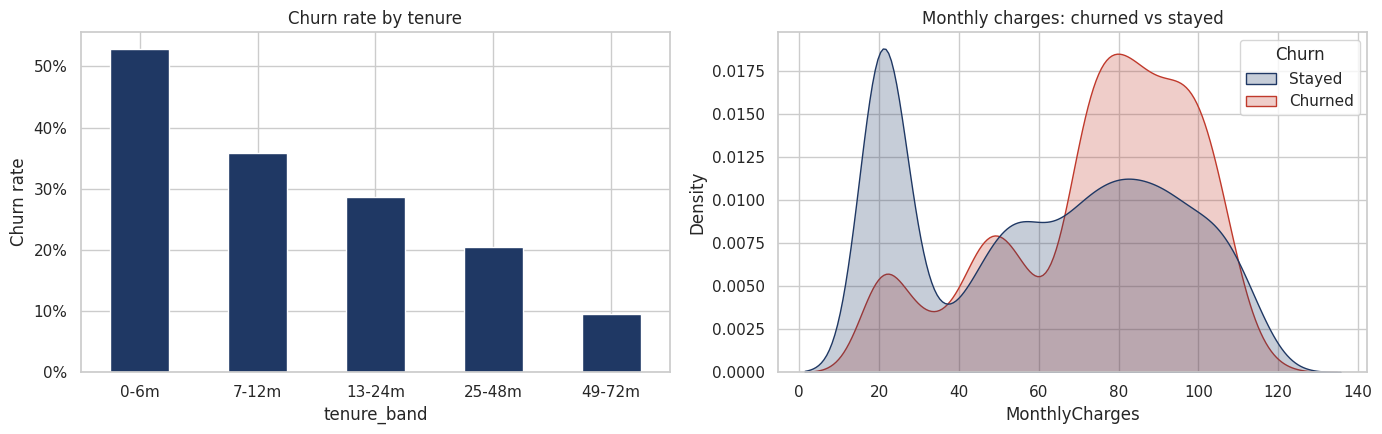

{'0-6m': 0.529, '7-12m': 0.359, '13-24m': 0.287, '25-48m': 0.204, '49-72m': 0.095}


In [8]:
df['tenure_band'] = pd.cut(df['tenure'], [-1, 6, 12, 24, 48, 72], labels=['0-6m', '7-12m', '13-24m', '25-48m', '49-72m'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df.groupby('tenure_band', observed=True)['Churn'].mean().plot(kind='bar', ax=axes[0], color='#1F3864')
axes[0].set_title('Churn rate by tenure'); axes[0].set_ylabel('Churn rate'); axes[0].tick_params(axis='x', rotation=0)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
sns.kdeplot(data=df, x='MonthlyCharges', hue=df['Churn'].map({0: 'Stayed', 1: 'Churned'}), fill=True,
            common_norm=False, ax=axes[1], palette={'Stayed': '#1F3864', 'Churned': '#C0392B'})
axes[1].set_title('Monthly charges: churned vs stayed')
plt.tight_layout(); plt.savefig(CHARTS + '02_tenure_and_charges.png', dpi=120); plt.show()

print(df.groupby('tenure_band', observed=True)['Churn'].mean().round(3).to_dict())
df = df.drop(columns='tenure_band')

**EDA insights**
- **Month-to-month contracts** churn far more than one- or two-year contracts.
- **Fiber-optic** internet customers churn more than DSL customers (possibly price or service-quality issues).
- Customers paying by **electronic check** churn the most.
- Customers **without tech support** churn more.
- **New customers (first 6 months)** are the highest-risk group; churn falls sharply with tenure.
- Churners tend to have **higher monthly charges**.

## 3. Train / test split and pre-processing pipeline

In [9]:
X = df.drop(columns='Churn')
y = df['Churn']

numeric = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical = [c for c in X.columns if c not in numeric]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Churn rate train / test: {:.3f} / {:.3f}'.format(y_train.mean(), y_test.mean()))

preprocess = ColumnTransformer([
    ('num', StandardScaler(), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), categorical),
])

Train: (5634, 19) | Test: (1409, 19)
Churn rate train / test: 0.265 / 0.265


**Why a Pipeline?** The scaler and encoder are fitted **only on the training data** inside each cross-validation fold. This prevents **data leakage** (test data influencing training) and lets us save one object that does all the steps for new customers.

**Stratified split** keeps the same churn rate in train and test.

## 4. Train and compare models (5-fold cross-validation)

In [10]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight='balanced',
                                            random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                                                    random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, clf in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')
    cv_results[name] = scores
    print(f'{name:20s} ROC-AUC = {scores.mean():.3f} ± {scores.std():.3f}')

Logistic Regression  ROC-AUC = 0.846 ± 0.012


Random Forest        ROC-AUC = 0.845 ± 0.009


Gradient Boosting    ROC-AUC = 0.848 ± 0.012


In [11]:
# Fit every model on the full training set and evaluate on the untouched test set
fitted, rows = {}, []
for name, clf in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', clf)]).fit(X_train, y_train)
    fitted[name] = pipe
    p = pipe.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    rows.append({'model': name, 'ROC-AUC': roc_auc_score(y_test, p), 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred)})
results = pd.DataFrame(rows).set_index('model').round(3)
results

,ROC-AUC,Precision,Recall,F1
model,,,,
Logistic Regression,0.841,0.504,0.783,0.614
Random Forest,0.841,0.549,0.735,0.629
Gradient Boosting,0.844,0.669,0.524,0.588


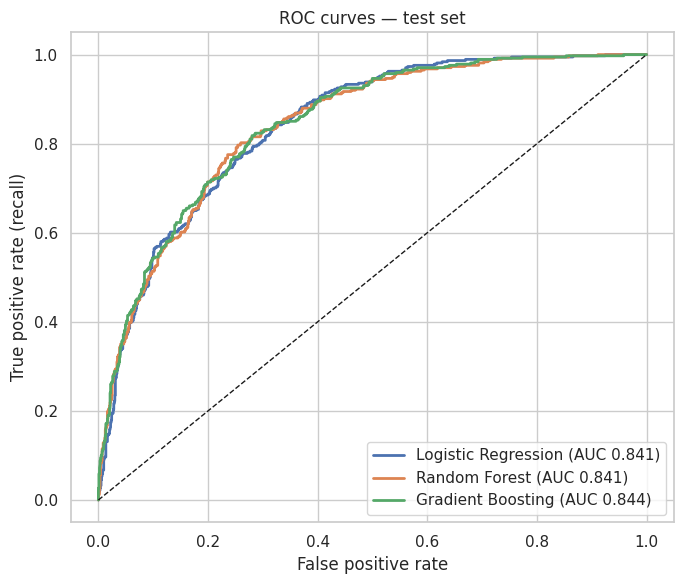

In [12]:
plt.figure(figsize=(7, 6))
for name, pipe in fitted.items():
    p = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC {roc_auc_score(y_test, p):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False positive rate'); plt.ylabel('True positive rate (recall)'); plt.title('ROC curves — test set')
plt.legend(); plt.tight_layout(); plt.savefig(CHARTS + '03_roc_comparison.png', dpi=120); plt.show()

**Model choice:** all three models score close to each other (AUC ≈ 0.84). Note that Logistic Regression and Random Forest use `class_weight='balanced'`, which gives them high **recall**, while Gradient Boosting (unweighted) has higher **precision** at the default 0.5 threshold — that is why their precision/recall look different even with similar AUC.

We pick the model with the **best cross-validated AUC** as the final model. When a simple model is about as good as a complex one, the simple one is often preferred because it is easier to explain to business users.

In [13]:
best_name = max(cv_results, key=lambda k: cv_results[k].mean())
best = fitted[best_name]
print('Selected model:', best_name)
p_test = best.predict_proba(X_test)[:, 1]

Selected model: Gradient Boosting


## 5. Choosing the decision threshold

The default threshold of 0.5 is not always right. The business question is: **is it worse to miss a churner, or to give a discount to someone who would have stayed anyway?** Missing a churner usually costs more, so we prefer **higher recall**.

In [14]:
th = pd.DataFrame([{'threshold': t,
                    'precision': precision_score(y_test, (p_test >= t).astype(int)),
                    'recall': recall_score(y_test, (p_test >= t).astype(int)),
                    'f1': f1_score(y_test, (p_test >= t).astype(int)),
                    'flagged_customers_%': (p_test >= t).mean()} for t in np.arange(0.2, 0.81, 0.05)]).round(3)
th

,threshold,precision,recall,f1,flagged_customers_%
0,0.20,0.485,0.848,0.617,0.463
1,0.25,0.516,0.799,0.627,0.412
2,0.30,0.530,0.746,0.620,0.373
3,0.35,0.563,0.709,0.627,0.334
4,0.40,0.597,0.652,0.623,0.290
5,0.45,0.625,0.580,0.602,0.246
6,0.50,0.669,0.524,0.588,0.208
7,0.55,0.705,0.447,0.547,0.168
8,0.60,0.747,0.372,0.496,0.132
9,0.65,0.755,0.297,0.426,0.104


Threshold with best F1: 0.25

              precision    recall  f1-score   support

      Stayed      0.910     0.729     0.809      1035
     Churned      0.516     0.799     0.627       374

    accuracy                          0.747      1409
   macro avg      0.713     0.764     0.718      1409
weighted avg      0.805     0.747     0.761      1409



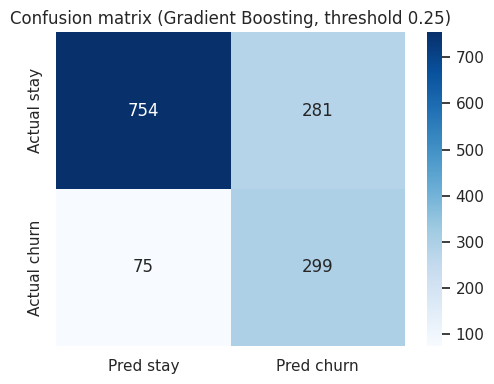

In [15]:
best_t = th.loc[th['f1'].idxmax(), 'threshold']
pred = (p_test >= best_t).astype(int)
print(f'Threshold with best F1: {best_t:.2f}\n')
print(classification_report(y_test, pred, target_names=['Stayed', 'Churned'], digits=3))

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred stay', 'Pred churn'], yticklabels=['Actual stay', 'Actual churn'])
plt.title(f'Confusion matrix ({best_name}, threshold {best_t:.2f})'); plt.tight_layout()
plt.savefig(CHARTS + '04_confusion_matrix.png', dpi=120); plt.show()

## 6. What drives churn? (model explainability)

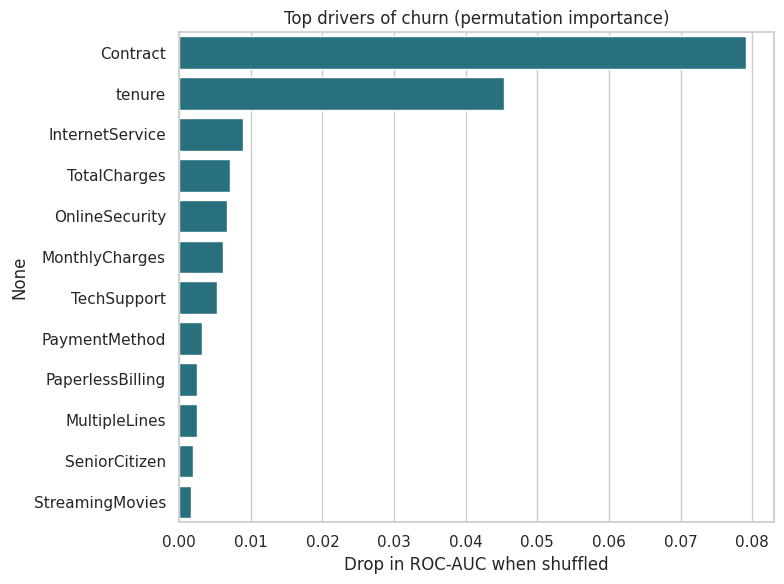

Contract            0.0791
tenure              0.0454
InternetService     0.0089
TotalCharges        0.0071
OnlineSecurity      0.0067
MonthlyCharges      0.0061
TechSupport         0.0053
PaymentMethod       0.0032
PaperlessBilling    0.0026
MultipleLines       0.0026
dtype: float64

In [16]:
# Permutation importance: how much the AUC drops when one column is shuffled
pi = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=imp.head(12).values, y=imp.head(12).index, color='#1B7A8C')
plt.title('Top drivers of churn (permutation importance)'); plt.xlabel('Drop in ROC-AUC when shuffled')
plt.tight_layout(); plt.savefig(CHARTS + '05_feature_importance.png', dpi=120); plt.show()
imp.head(10).round(4)

In [17]:
# Direction of each effect from the Logistic Regression coefficients (positive = increases churn risk)
lr = fitted['Logistic Regression']
names = lr.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(lr.named_steps['model'].coef_[0], index=names).sort_values()
pd.concat([coefs.head(6), coefs.tail(6)]).round(3).to_frame('coefficient')

,coefficient
num__tenure,-1.138
cat__Contract_Two year,-0.808
num__MonthlyCharges,-0.663
cat__InternetService_DSL,-0.655
cat__OnlineSecurity_No internet service,-0.309
cat__StreamingTV_No internet service,-0.309
cat__StreamingTV_Yes,0.225
cat__StreamingMovies_Yes,0.238
cat__PaperlessBilling_Yes,0.336
num__TotalCharges,0.471


**How to read this:** month-to-month contracts and fiber-optic internet push churn risk **up**; long tenure and two-year contracts push it **down**.

⚠️ Notice `MonthlyCharges` has a *negative* coefficient even though the EDA showed churners pay more. This is **multicollinearity**: `TotalCharges ≈ tenure × MonthlyCharges`, so the three columns overlap and their individual signs can flip. Read them together, and use the EDA for the direction of each effect. (A good fix in a next iteration: drop `TotalCharges` or check the Variance Inflation Factor, VIF.)

## 7. Business value — lift and gains

In [18]:
# If the retention team can only call the top X% riskiest customers, what share of churners do they reach?
order = np.argsort(-p_test)
y_sorted = y_test.values[order]
deciles = np.array_split(y_sorted, 10)
gains = pd.DataFrame({'decile': range(1, 11),
                      'churn_rate': [d.mean() for d in deciles],
                      'cumulative_%_of_churners': np.cumsum([d.sum() for d in deciles]) / y_sorted.sum()})
gains['lift'] = gains['churn_rate'] / y_test.mean()
gains.round(3)

,decile,churn_rate,cumulative_%_of_churners,lift
0,1,0.766,0.289,2.886
1,2,0.596,0.513,2.244
2,3,0.390,0.660,1.470
3,4,0.319,0.781,1.202
4,5,0.213,0.861,0.802
5,6,0.170,0.925,0.641
6,7,0.121,0.971,0.454
7,8,0.057,0.992,0.214
8,9,0.014,0.997,0.053
9,10,0.007,1.000,0.027


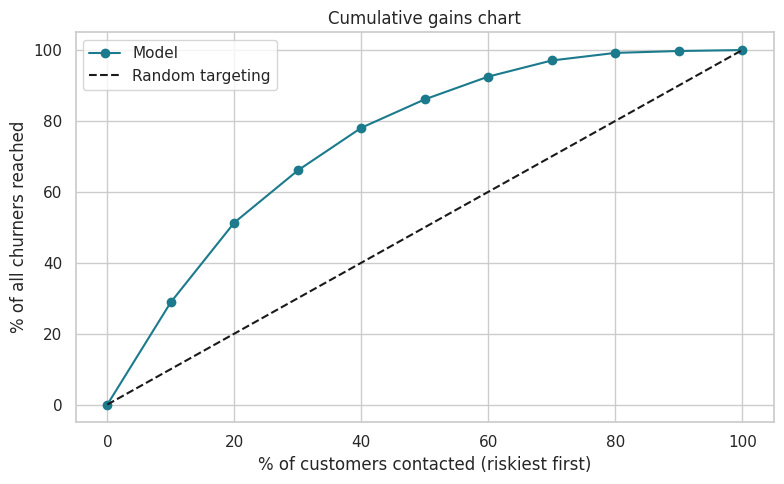

Contacting the riskiest 30% of customers reaches 66% of all churners (random targeting would reach 30%).


In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot([0] + list(gains['decile'] * 10), [0] + list(gains['cumulative_%_of_churners'] * 100), marker='o', color='#1B7A8C', label='Model')
ax.plot([0, 100], [0, 100], 'k--', label='Random targeting')
ax.set_xlabel('% of customers contacted (riskiest first)'); ax.set_ylabel('% of all churners reached')
ax.set_title('Cumulative gains chart'); ax.legend(); plt.tight_layout()
plt.savefig(CHARTS + '06_gains_chart.png', dpi=120); plt.show()

top30 = gains.loc[2, 'cumulative_%_of_churners']
print(f'Contacting the riskiest 30% of customers reaches {top30:.0%} of all churners (random targeting would reach 30%).')

## 8. Save the model and score customers

In [20]:
joblib.dump({'pipeline': best, 'threshold': float(best_t), 'model_name': best_name}, 'models/churn_model.joblib')

scored = X_test.copy()
scored['churn_probability'] = p_test.round(3)
scored['risk_segment'] = pd.cut(scored['churn_probability'], [0, 0.3, 0.6, 1.0], labels=['Low', 'Medium', 'High'], include_lowest=True)
scored['actual_churn'] = y_test.values
scored.sort_values('churn_probability', ascending=False).to_csv('outputs/test_customers_scored.csv', index=False)
print(scored['risk_segment'].value_counts())
scored.groupby('risk_segment', observed=True)['actual_churn'].mean().round(3)

risk_segment
Low       884
Medium    340
High      185
Name: count, dtype: int64


risk_segment
Low       0.107
Medium    0.415
High      0.746
Name: actual_churn, dtype: float64

## 9. Conclusions & recommendations

**Model:** the selected model ranks churn risk well on unseen data (test ROC-AUC ≈ 0.84). Contacting the riskiest 30% of customers reaches roughly two-thirds of all churners — about **2× better than random targeting**.

**Main churn drivers:** contract type (month-to-month), short tenure, fiber-optic internet, electronic-check payment, lack of tech support / online security, and higher monthly charges.

**Recommendations for the business**
1. Offer **discounts to move month-to-month customers onto 1- or 2-year contracts**.
2. Build a **first-6-months onboarding programme** — new customers are the most likely to leave.
3. Bundle **tech support / online security** for fiber customers.
4. Encourage **auto-pay** (bank transfer / credit card) instead of electronic check.
5. Run the model **monthly** and send the "High risk" list to the retention team.

**Next steps:** add usage and complaint data, try hyper-parameter tuning (GridSearchCV), and track model performance over time.